# Targeted nose, ear, head-shape, layout, and eye-shape cues

The model has 729 recipes and three eye shapes. The training generator favors
dots for cows, oval pupils for cats, and arches for humans.

This experiment extends the category-cue comparison with **explicit feature
statements**. The fixed learned category-mixture prior is used in every condition.
The cue contributes a separate likelihood factor, with assumed reliability .95.
For each feature, a cue naming either wrong value is tested alongside the correct
cue and no cue. The prior coefficient is 1 throughout.

The matched observation conditions deliberately conceal or reveal the pixels that
distinguish the target feature alternatives. Those diagnostic pixels are computed
by varying the feature through ALL values with other features fixed. The mask
therefore creates engineered ambiguity, not an unbiased random-occlusion benchmark.
A one-pixel margin is included. All other pixels use a random 5x5-block visibility
mask at probability .35. Noise is 5% independent flips, with the same underlying
flip field in the matched conditions. Three canonical held-out recipes are used,
one per synthetic sampling category, with seeds 17/37/67.

Every reconstruction uses full-candidate inference and VSA image evidence. The
feature likelihood is P(statement=v | feature=v)=.95 and .025 for each other value.
The cue is finite evidence, so visible contradictions can outweigh it. Grey pixels
show posterior uncertainty. P(cued value) marginalizes over all complete recipes.

The source below reruns the experiment and regenerates the PNGs and metrics. The
existing model and original notebook are preserved.


In [1]:
"""Run feature-specific cue interventions without changing the source model."""
from pathlib import Path
import base64
import csv
import json
import sys
import zipfile

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import nbformat
import numpy as np
from scipy.ndimage import binary_dilation

ROOT = Path.cwd().resolve()
if (ROOT / "BayesContourProcessing" / "contour_models").is_dir():
    ROOT = ROOT / "BayesContourProcessing"
while not (ROOT / "contour_models" / "face_recipes_and_observations.py").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook inside the contour-processing project.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from contour_models.face_recipes_and_observations import *
from contour_models.vsa_inference import PixelVSA, posterior, factor_marginals

OUT = ROOT / 'outputs' / 'targeted_feature_cues_2026-11-16'
OUT.mkdir(exist_ok=True)
SEEDS = (17, 37, 67)
FEATURES = (3, 1, 0, 4, 5)
RELIABILITY = .95
NOISE = .05
library = make_library(size=40, seed=7)
ids, labels = sample_training(library, n_per_class=250, seed=11)
bank = fit_priors(library, ids, labels, category_learning="counts")
encoder = PixelVSA(40, dim=512, seed=17)


def cue_posterior(loglik, feature, value):
    # A categorical cue channel. The model assumes P(cue says v | true v)=.95.
    # Each other possible statement shares the remaining .05 probability.
    cue_loglik = np.log(np.where(library.states[:, feature] == value,
                       RELIABILITY, (1-RELIABILITY)/(CARDINALITIES[feature]-1)))
    return posterior(loglik + cue_loglik, bank.logpriors['category'], strength=1.)


def run_case(category, feature):
    state_id = int(library.test_ids[np.argmax(library.teacher_logp[category, library.test_ids])])
    state = library.states[state_id]
    truth = library.images[state_id]
    counterfactuals = []
    counterfactual_ids = []
    for value in range(CARDINALITIES[feature]):
        modified = state.copy()
        modified[feature] = value
        index = int(np.flatnonzero(np.all(library.states == modified, axis=1))[0])
        counterfactual_ids.append(index)
        counterfactuals.append(library.images[index])
    # The same comparison mask is built from ALL alternatives, independent of
    # which target value is true. This creates controlled feature ambiguity.
    alternatives = np.stack(counterfactuals)
    diagnostic = alternatives.max(axis=0) != alternatives.min(axis=0)
    region = binary_dilation(diagnostic, iterations=1)
    seed = SEEDS[category]
    background_mask = block_mask(40, .35, np.random.default_rng(seed), block=5)
    masks = {'concealed': background_mask & ~region,
             'revealed': background_mask | region}
    actual_value = int(state[feature])
    wrong_values = [v for v in range(CARDINALITIES[feature]) if v != actual_value]
    results = []
    for visibility_mode, mask in masks.items():
        y = observe(truth, mask, NOISE, np.random.default_rng(seed+100))
        ll = encoder.evidence_scores(library.images, y, mask, NOISE, 'vsa')
        if visibility_mode == 'concealed':
            assert np.ptp(ll[counterfactual_ids]) < 1e-5, 'Hidden target leaked into evidence'
        q_none = posterior(ll, bank.logpriors['category'], 1.)
        conditions = [('No cue', None, q_none)]
        for label, value in [('Correct cue', actual_value), *[(f'Wrong cue {i+1}', v) for i,v in enumerate(wrong_values)]]:
            conditions.append((label, value, cue_posterior(ll, feature, value)))
        for label, value, q in conditions:
            assert np.isclose(q.sum(), 1)
        results.append(dict(category=category, feature=feature, seed=seed, state_id=state_id,
                            true_value=actual_value, mode=visibility_mode, truth=truth,
                            mask=mask, observed=y, conditions=conditions))
    return results


def render_row(axes, result):
    j = result['feature']
    show_completion(axes[0], result['truth'], 'Truth\n'+FACTOR_VALUES[j][result['true_value']])
    show_observation(axes[1], result['observed'], result['mask'],
                     f"Target {result['mode']}\n{result['mask'].mean():.0%} visible")
    for ax, (label, value, q) in zip(axes[2:], result['conditions']):
        marginal = factor_marginals(q, library.states, CARDINALITIES)[j]
        winner_value = int(library.states[np.argmax(q), j])
        if value is None:
            details = f"MAP {FACTOR_VALUES[j][winner_value]}"
        else:
            details = f"{FACTOR_VALUES[j][value]}\nP(cued value)={marginal[value]:.2f}"
        show_completion(ax, prediction(q, library.images), label+'\n'+details)


results = []
records = []
for feature in FEATURES:
    feature_results = []
    for category in range(3):
        for result in run_case(category, feature):
            feature_results.append(result)
            results.append(result)
            folder = OUT / f"{FACTOR_NAMES[feature].replace(' ', '_')}_{CLASS_NAMES[category]}_{result['mode']}"
            folder.mkdir(exist_ok=True)
            fig, axes = plt.subplots(1, 6, figsize=(14, 3.8))
            render_row(axes, result)
            fig.suptitle(f"{FACTOR_NAMES[feature]} | {CLASS_NAMES[category]} | seed {result['seed']} | "
                         f"feature-cue reliability {RELIABILITY:.0%}", fontsize=13)
            fig.tight_layout(rect=(0, 0, 1, .87))
            fig.savefig(folder/'comparison.png', dpi=150, bbox_inches='tight')
            plt.close(fig)
            result['folder'] = folder.name
            for label, value, q in result['conditions']:
                marginal = factor_marginals(q, library.states, CARDINALITIES)[feature]
                winner = int(np.argmax(q))
                metrics = completion_metrics(prediction(q, library.images), result['truth'],
                                             result['observed'], result['mask'])
                records.append(dict(feature=FACTOR_NAMES[feature], face=CLASS_NAMES[category],
                   seed=result['seed'], state_id=result['state_id'], mode=result['mode'],
                   visibility=float(result['mask'].mean()), condition=label,
                   true_value=FACTOR_VALUES[feature][result['true_value']],
                   cued_value='' if value is None else FACTOR_VALUES[feature][value],
                   p_cued='' if value is None else float(marginal[value]),
                   p_true=float(marginal[result['true_value']]), map_state=winner,
                   map_feature=FACTOR_VALUES[feature][int(library.states[winner, feature])], **metrics))
    fig, axes = plt.subplots(6, 6, figsize=(14, 15))
    for row, result in enumerate(feature_results):
        render_row(axes[row], result)
        axes[row,0].text(-.12,.5, CLASS_NAMES[result['category']],
                         transform=axes[row,0].transAxes,ha='right',va='center',fontsize=10)
    fig.suptitle(f"Targeted {FACTOR_NAMES[feature]} cues | concealed vs revealed evidence\n"
                 'Posterior means | same base prior and cue reliability in every comparison', fontsize=15)
    fig.tight_layout(rect=(.07,0,1,.96))
    fig.savefig(OUT/f"overview_{FACTOR_NAMES[feature].replace(' ', '_')}.png", dpi=130, bbox_inches='tight')
    plt.close(fig)
    print('Finished', FACTOR_NAMES[feature], flush=True)

with (OUT/'metrics.csv').open('w',newline='',encoding='utf-8') as handle:
    writer=csv.DictWriter(handle,fieldnames=list(records[0]))
    writer.writeheader();writer.writerows(records)


Finished nose shape
Finished ear shape
Finished head shape
Finished layout
Finished eye shape


## Nose Shape

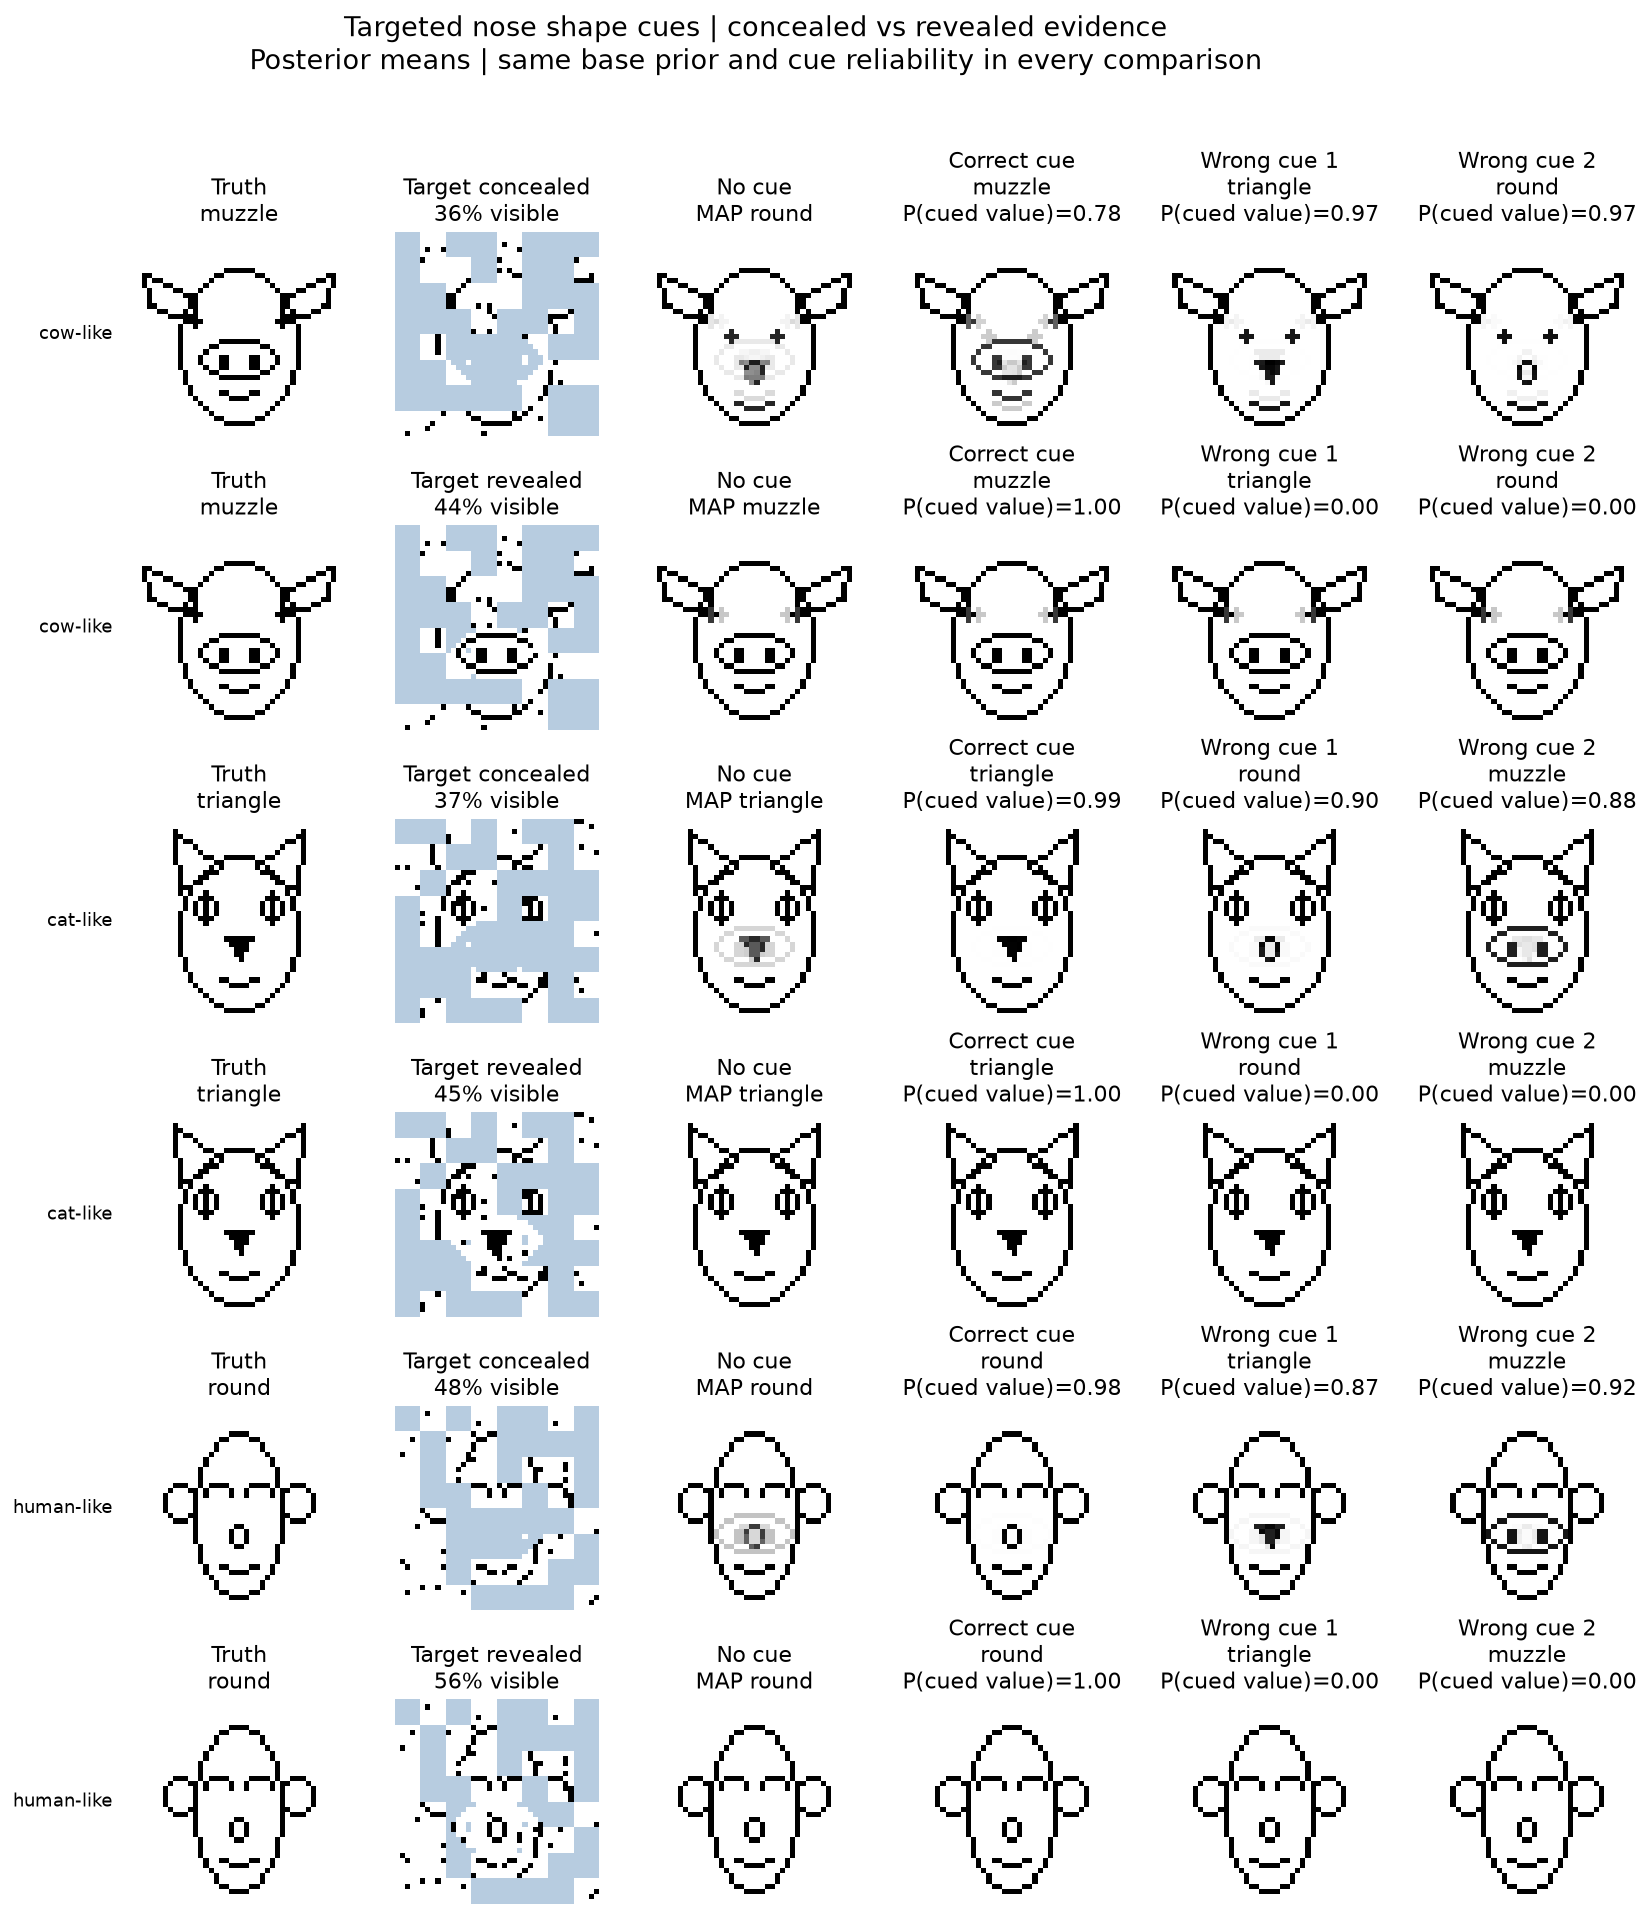

In [2]:
from IPython.display import display, Image
display(Image(filename=str(OUT / 'overview_nose_shape.png')))

## Ear Shape

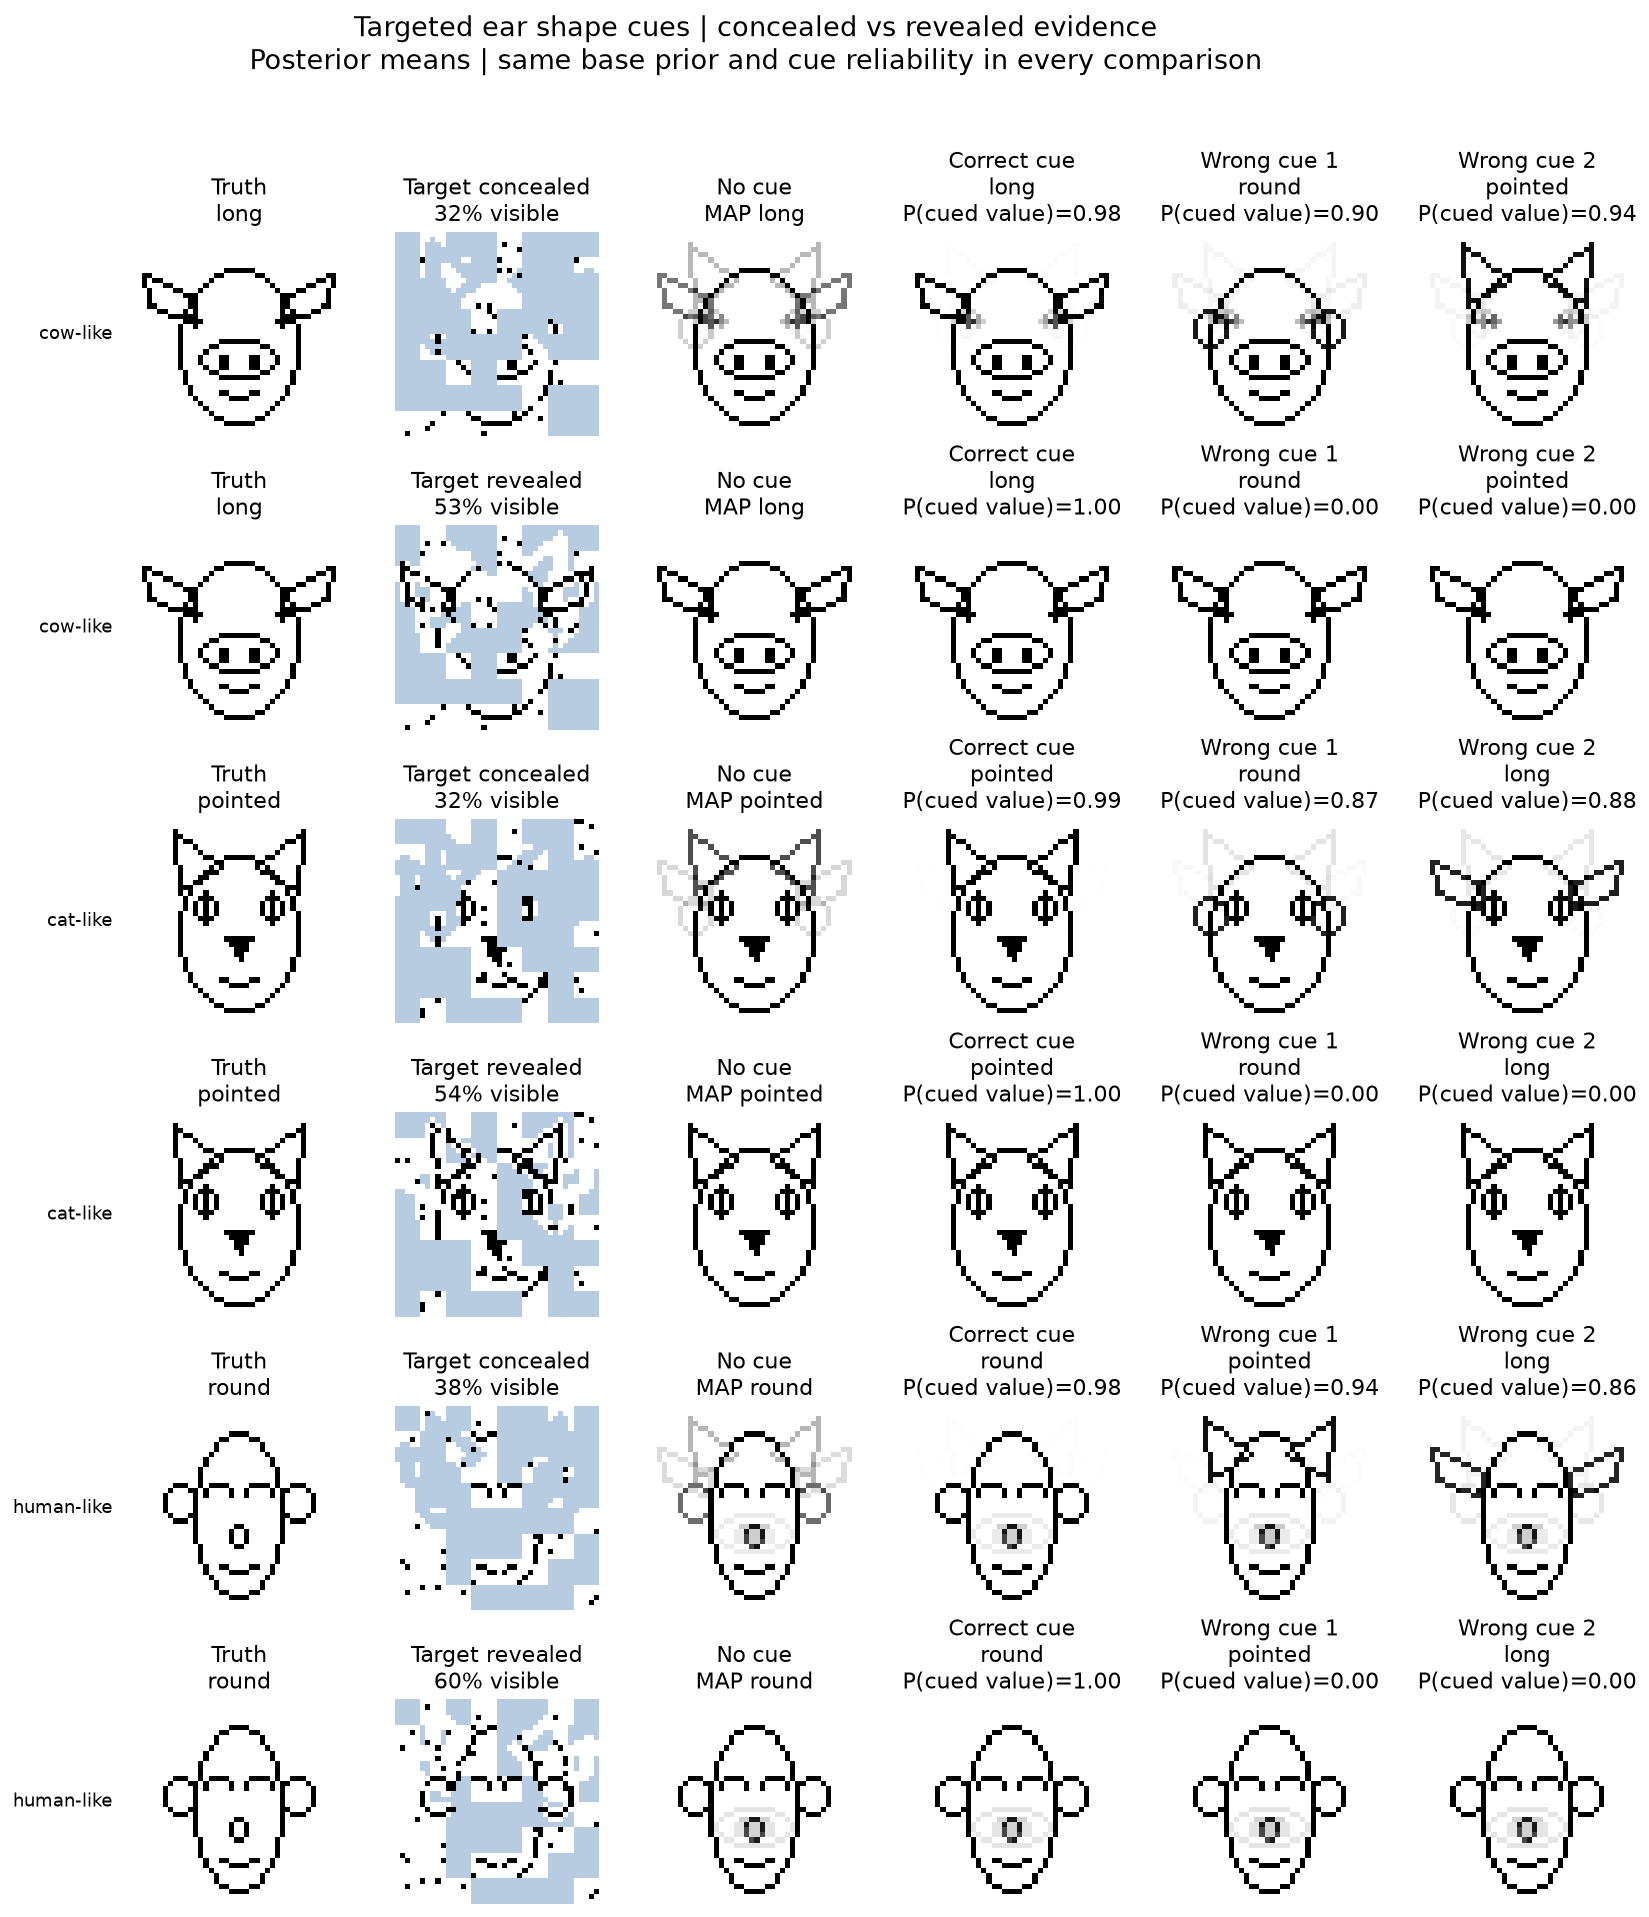

In [3]:
from IPython.display import display, Image
display(Image(filename=str(OUT / 'overview_ear_shape.png')))

## Head Shape

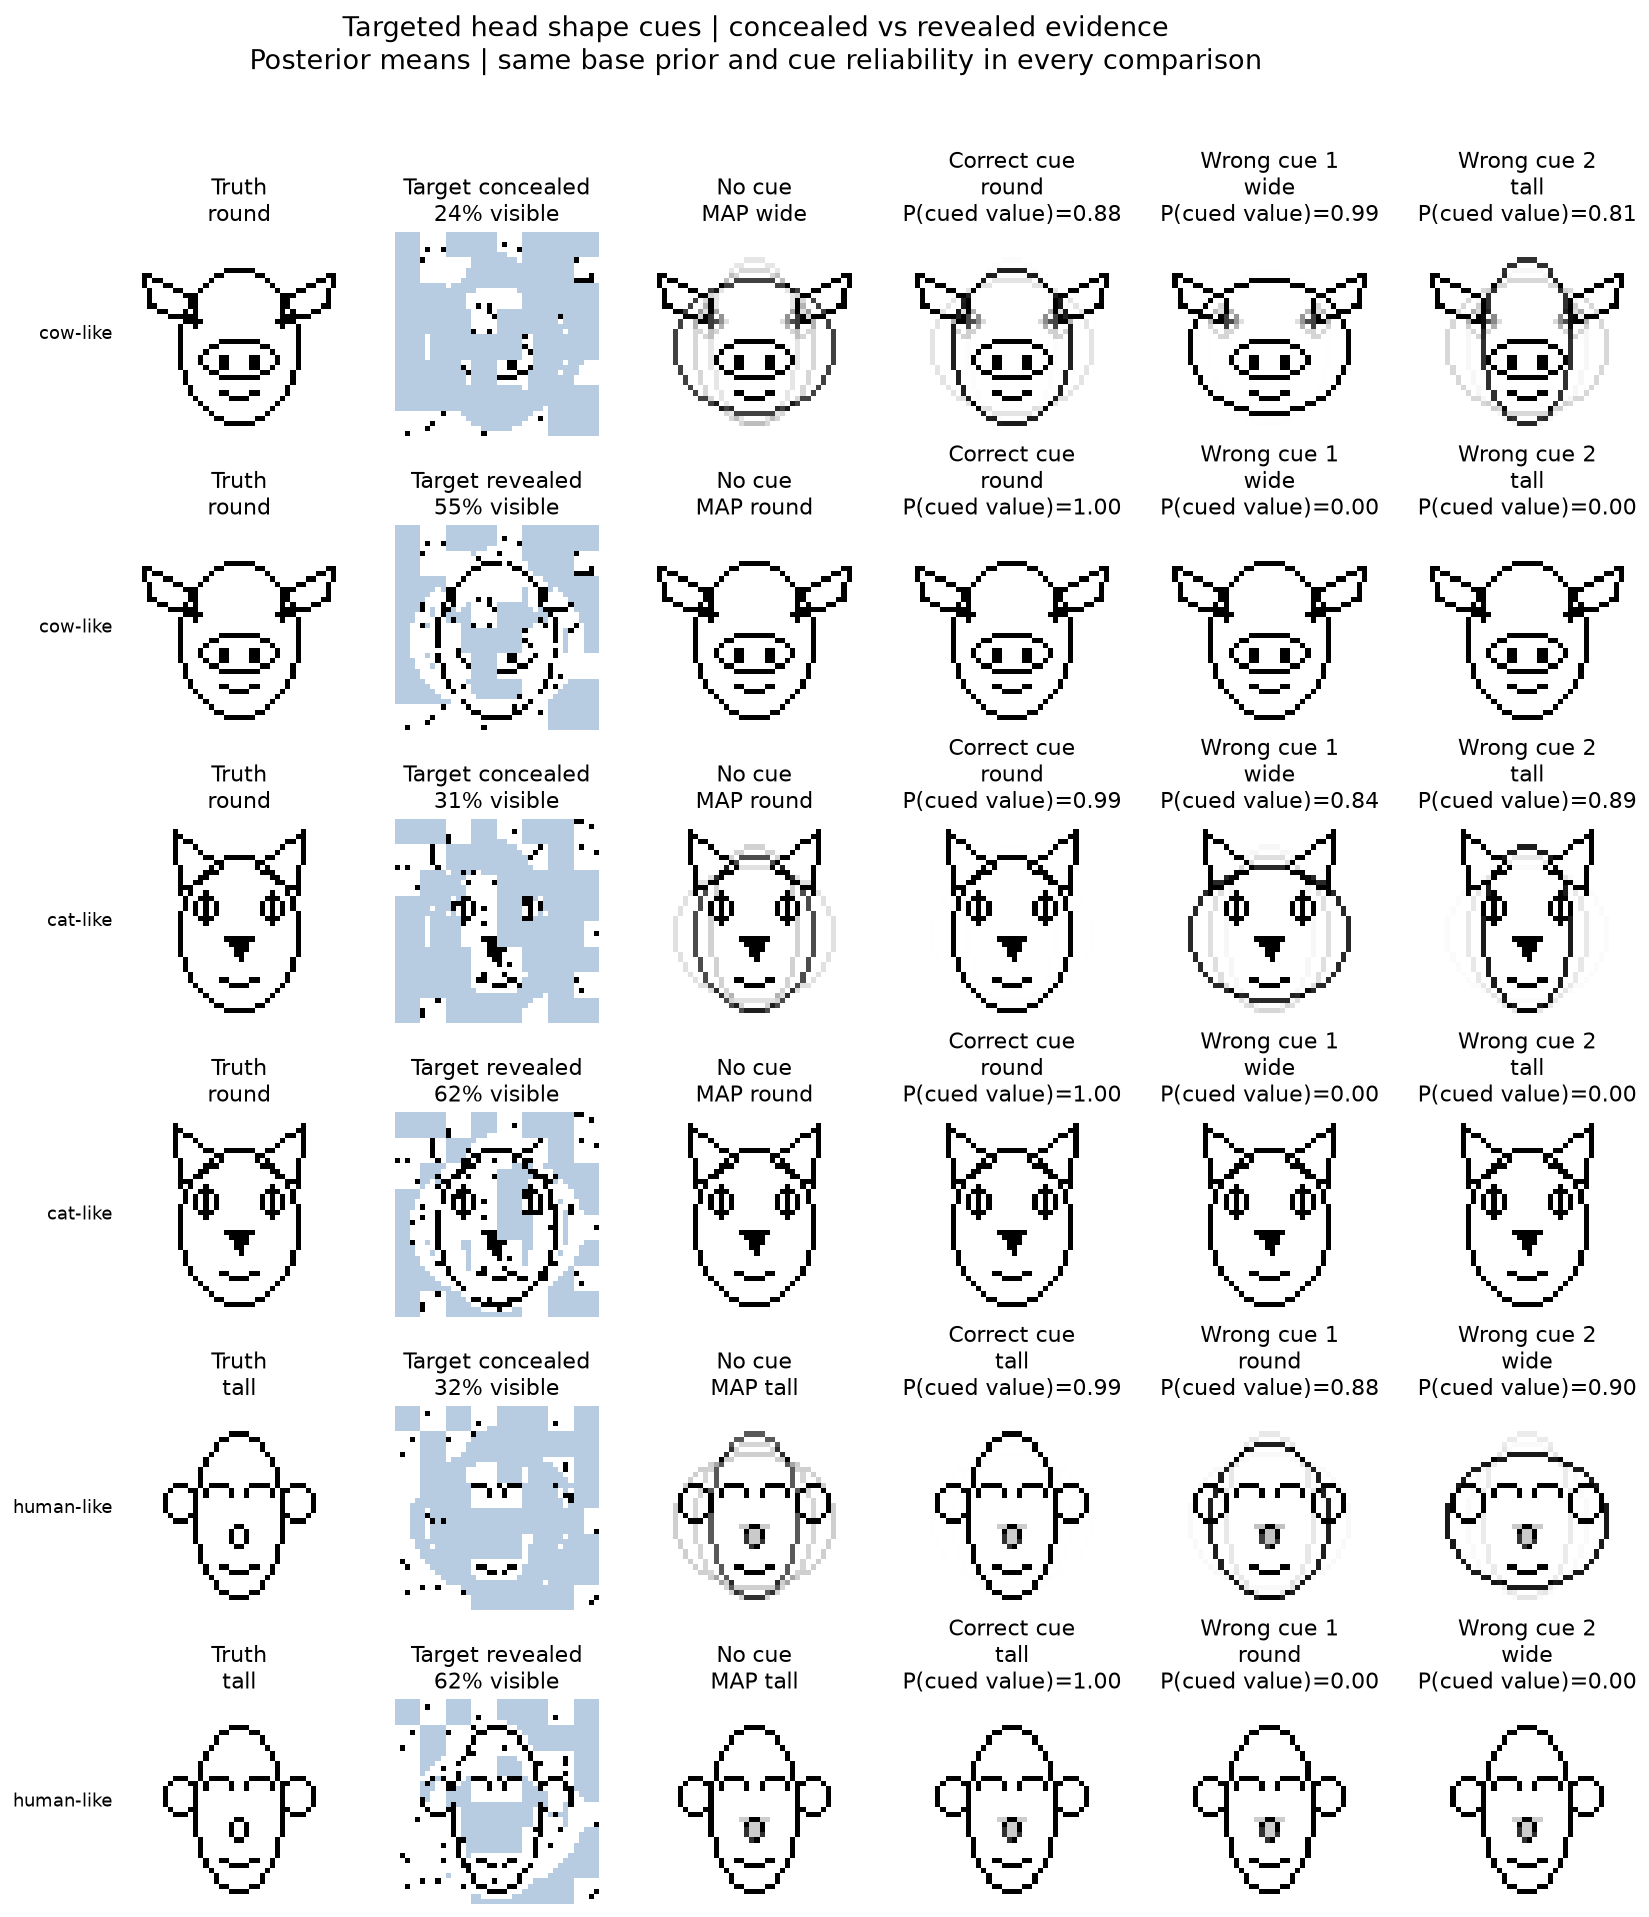

In [4]:
from IPython.display import display, Image
display(Image(filename=str(OUT / 'overview_head_shape.png')))

## Layout

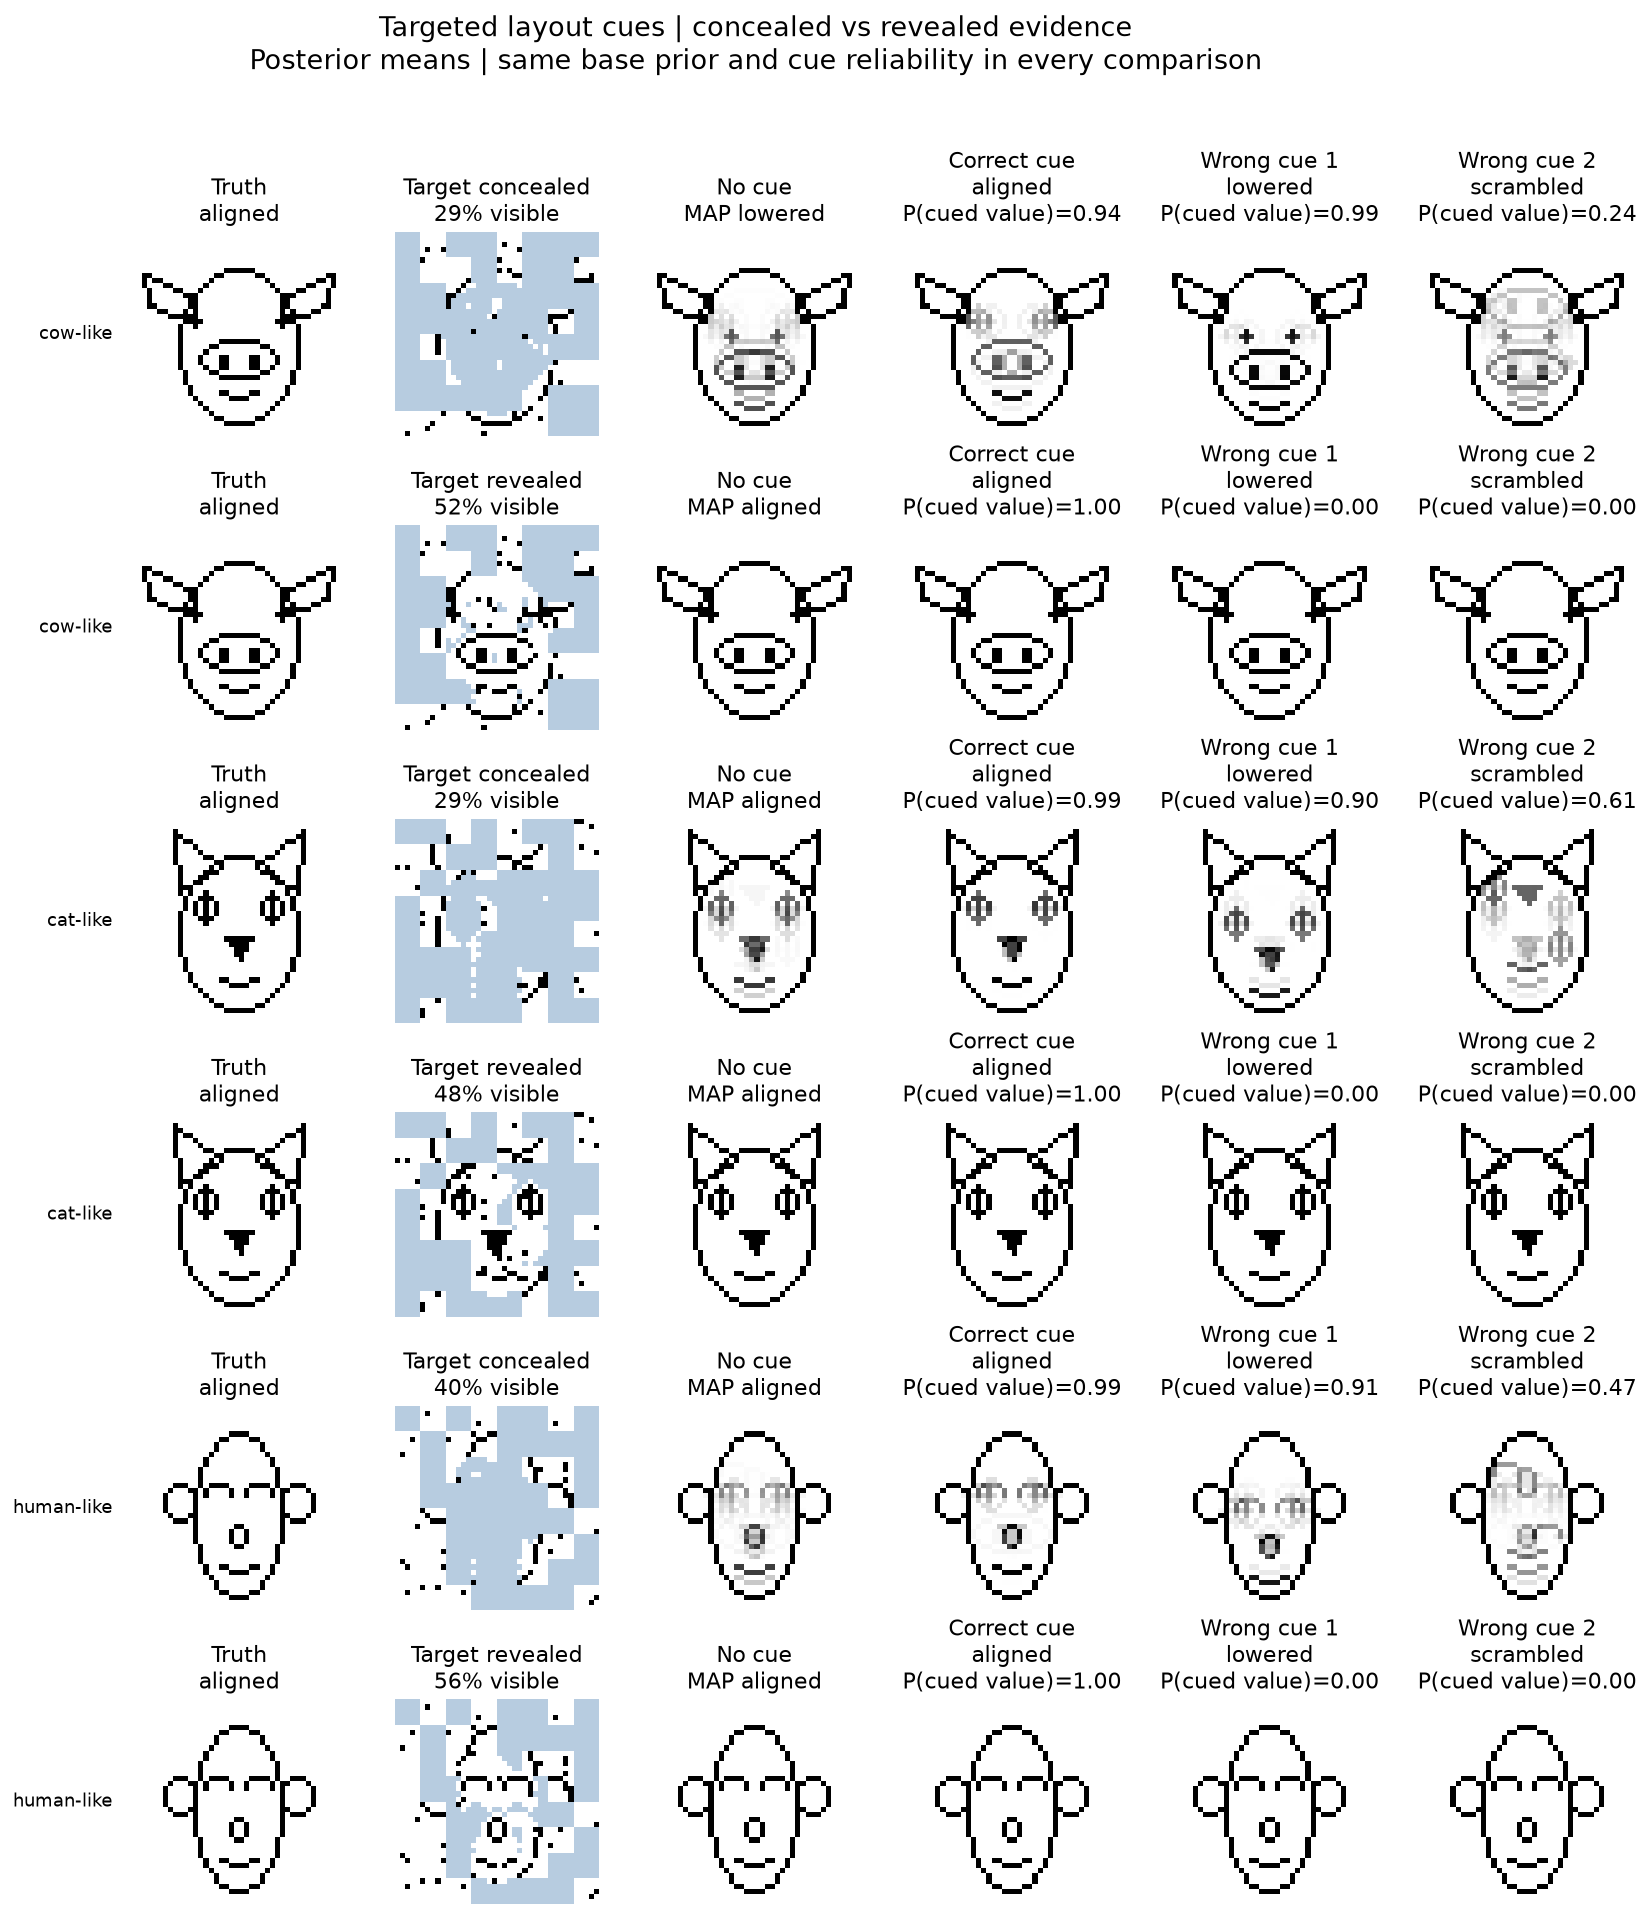

In [5]:
from IPython.display import display, Image
display(Image(filename=str(OUT / 'overview_layout.png')))

## Eye Shape

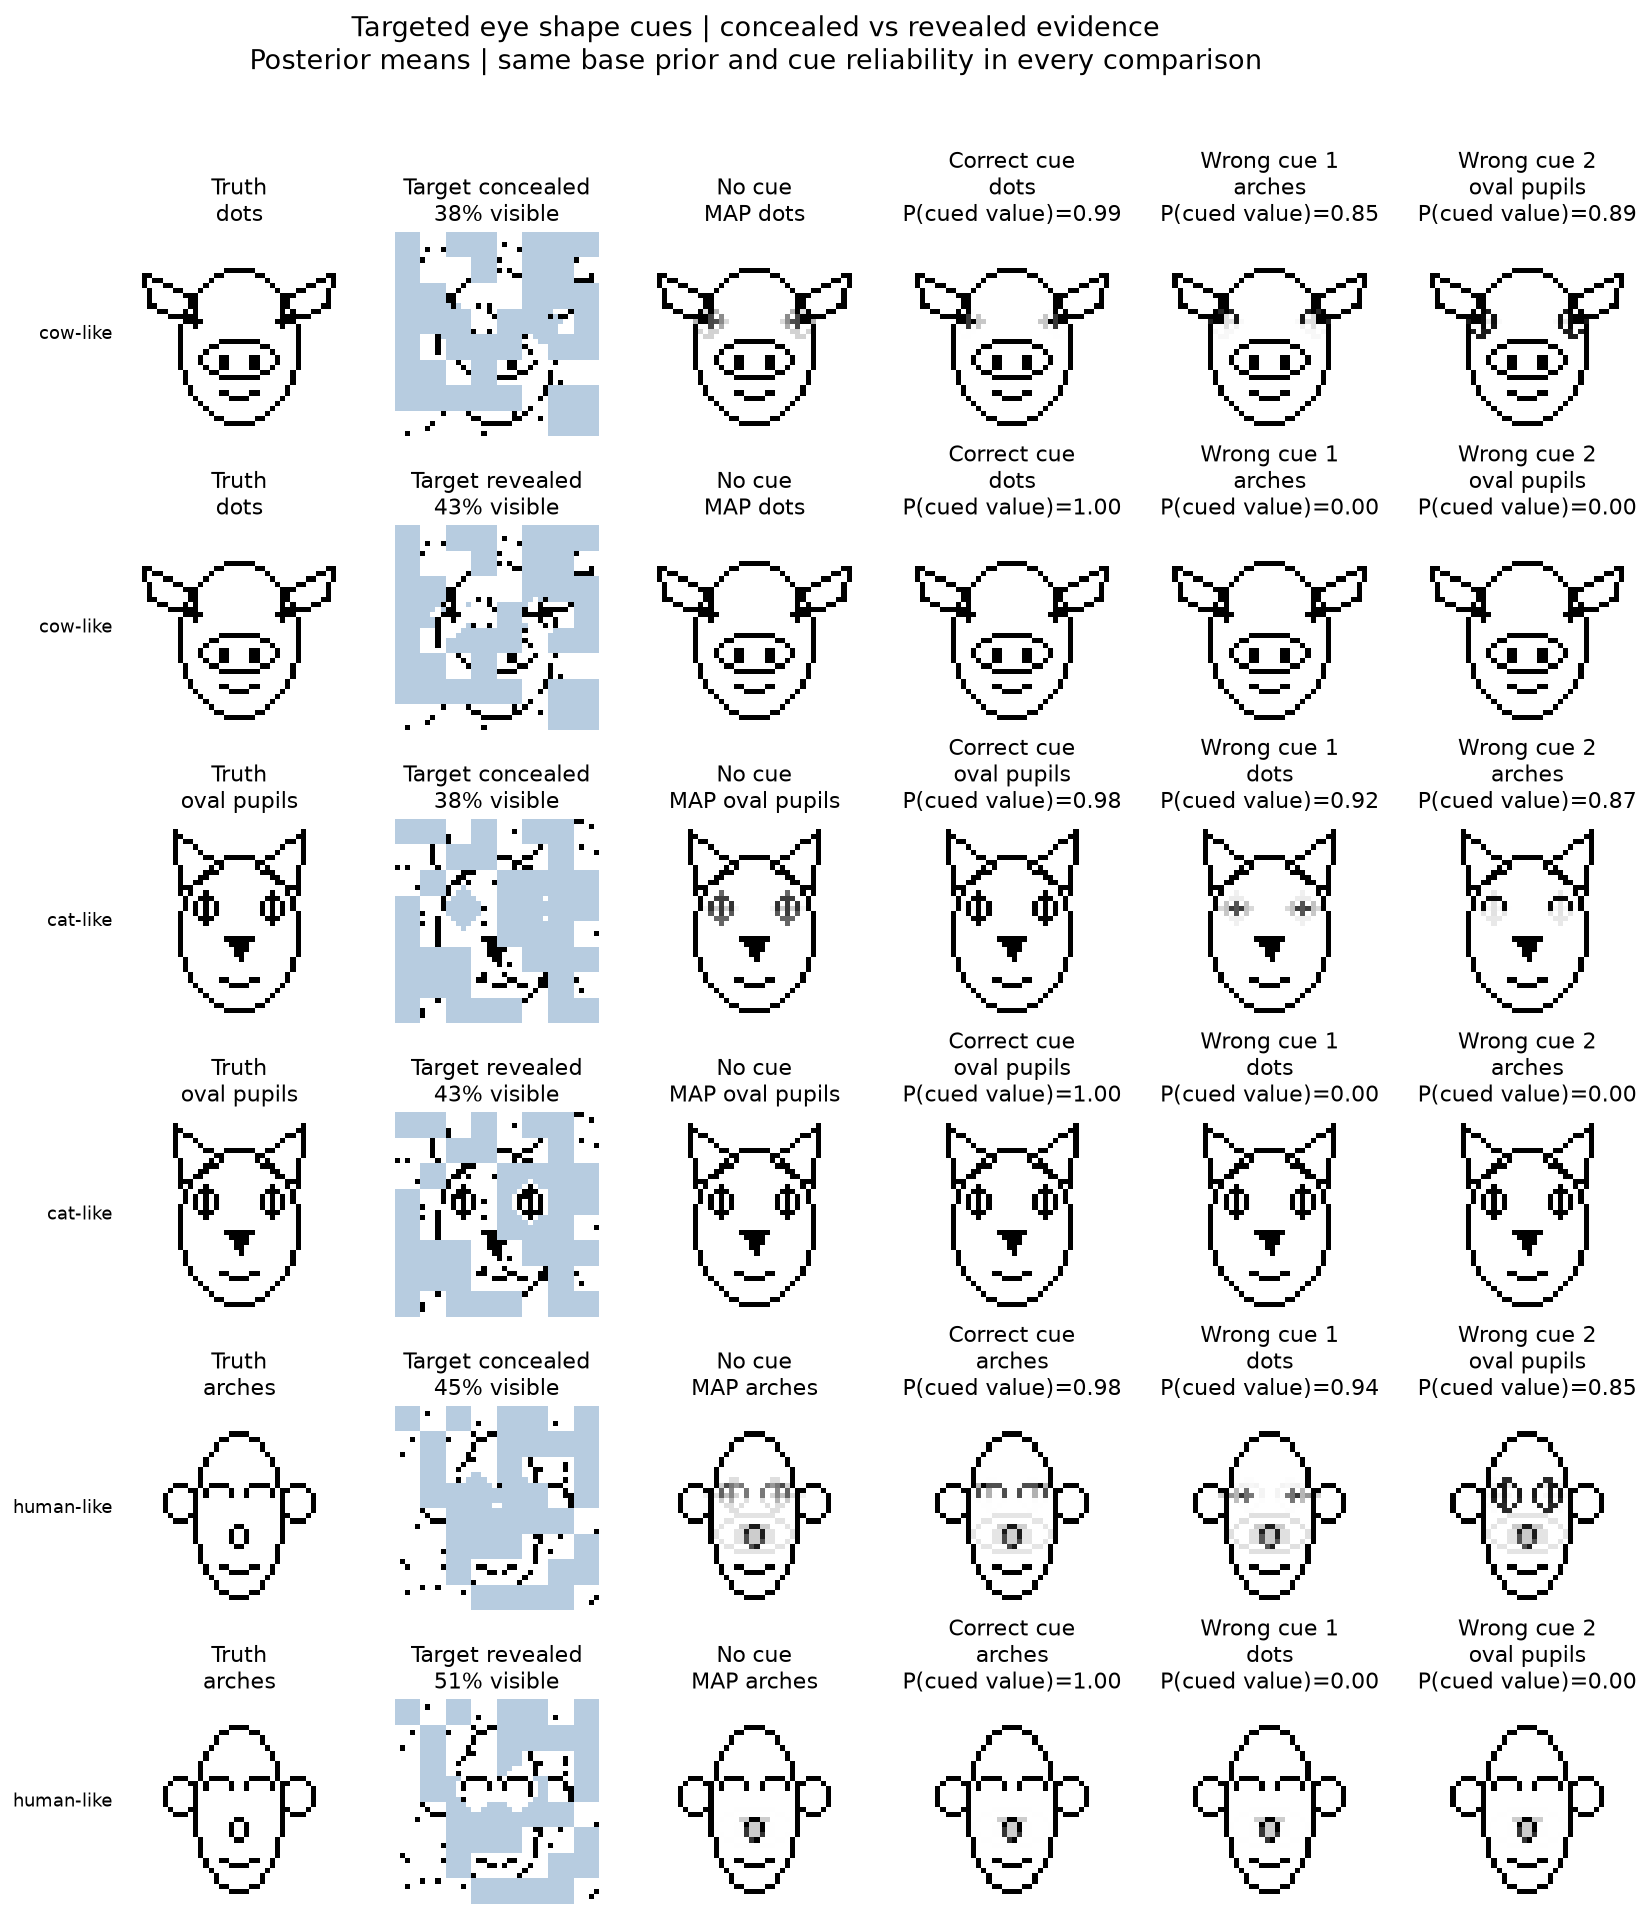

In [6]:
from IPython.display import display, Image
display(Image(filename=str(OUT / 'overview_eye_shape.png')))